# Proyek Analisis Sentimen: Ulasan Aplikasi WeTV
- **Nama:** Imam Riyadi
- **Email:** imaammriyadi@gmail.com
- **ID Dicoding:** mamyadi

## Deskripsi Proyek
Notebook ini memuat alur lengkap analisis sentimen ulasan aplikasi streaming WeTV (`com.tencent.qqlivei18n`) yang dikumpulkan langsung dari Google Play Store. Alur analisis mencakup data loading, inspeksi tipe data, seleksi fitur esensial, pembersihan missing value & duplikasi, text preprocessing, pelabelan sentimen objektif berbasis leksikon (3 kelas: Positif, Netral, Negatif), ekstraksi fitur komparatif, pelatihan 3 skema model (ML & Deep Learning BiLSTM), hingga pengujian inferensi data baru.

# 1. Loading & Inspeksi Dataset
Tahap ini memuat data mentah hasil penarikan ulasan (`wetv-reviews-raw.csv`), melakukan inspeksi awal struktur DataFrame (tipe data, dimensi, dan missing values), menyeleksi fitur utama (`content` dan `score`), serta memvalidasi kesesuaian tipe data.

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
# Load dataset hasil scraping
raw_csv_path = "wetv-reviews-raw.csv"
df_raw = pd.read_csv(raw_csv_path)

print(f"Dataset berhasil dimuat!")
print(f"Dimensi data mentah : {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom")
print("-" * 50)
df_raw.head()

Dataset berhasil dimuat!
Dimensi data mentah : 12000 baris, 11 kolom
--------------------------------------------------


,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion
0,21c5057c-bace-4f6a-a7a5-df43a5dd09ef,Mas Arif Syawal,https://play-lh.googleusercontent.com/a/ACg8oc...,Sangat bagus dan membantu.,5,0,NaN,2026-10-04 11:35:07,"Halo, Kak! Terima kasih untuk rating dan revie...",2026-10-04 14:01:42,NaN
1,7e7c2aa1-93f3-42ff-96d1-a69e955d3ab5,Lucky Rada,https://play-lh.googleusercontent.com/a/ACg8oc...,"sudah beli kok masih proses sampai sekarang, g...",1,0,5.39.5.18470,2026-10-04 08:36:11,"Hai, Kak. Mohon maaf ya. Pastikan Kakak sudah ...",2026-10-03 00:31:49,5.39.5.18470
2,3617801f-f64d-45ba-99a1-d4600c6aca4d,Asep Sunandar,https://play-lh.googleusercontent.com/a-/ALV-U...,Sudah bayar buat langganan VIP tapi masih bany...,1,0,NaN,2026-10-04 00:48:08,"Hi Kak, Saat ini bisa coba ke menu setting > I...",2026-10-04 00:33:59,NaN
3,c7f4c6e9-dce8-4b07-b21d-7a68747ec1d0,Ano Inuyasha,https://play-lh.googleusercontent.com/a-/ALV-U...,loncat terus ke app iklan.. 😤,1,1,3.2.4.58371,2026-10-03 22:15:36,"Hi Kak, Saat ini bisa coba ke menu setting > I...",2026-10-04 00:32:44,3.2.4.58371
4,6847770d-3852-412b-9bf9-e07000ee4830,Achmad Taufiq T (‫تَوْفِيقِي‬‎),https://play-lh.googleusercontent.com/a-/ALV-U...,sudah langganan vip tapi masih muncul iklan sa...,1,0,5.39.5.18470,2026-10-03 17:21:06,"Hai, kak! Mohon maaf atas kendalanya. Untuk pe...",2026-10-03 18:33:33,5.39.5.18470


In [2]:
# Menampilkan ringkasan tipe data dan keberadaan null
print("--- Ringkasan Struktur Data Mentah ---")
df_raw.info()

print("\n--- Jumlah Nilai Kosong (Missing Values) Per Kolom ---")
print(df_raw.isnull().sum())

--- Ringkasan Struktur Data Mentah ---
<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   reviewId              12000 non-null  str  
 1   userName              12000 non-null  str  
 2   userImage             12000 non-null  str  
 3   content               12000 non-null  str  
 4   score                 12000 non-null  int64
 5   thumbsUpCount         12000 non-null  int64
 6   reviewCreatedVersion  7695 non-null   str  
 7   at                    12000 non-null  str  
 8   replyContent          11984 non-null  str  
 9   repliedAt             11984 non-null  str  
 10  appVersion            7695 non-null   str  
dtypes: int64(2), str(9)
memory usage: 1.0 MB

--- Jumlah Nilai Kosong (Missing Values) Per Kolom ---
reviewId                   0
userName                   0
userImage                  0
content                    0
score   

In [3]:
# Mengganti kolom tanggal ke tipe datetime
df_raw['at'] = pd.to_datetime(df_raw['at'], errors='coerce')
df_raw['repliedAt'] = pd.to_datetime(df_raw['repliedAt'], errors='coerce')

# Mengisi nilai kosong (Missing Values) tanpa menghapus baris ulasan
# Mengisi versi aplikasi yang tidak terdeteksi
df_raw['appVersion'] = df_raw['appVersion'].fillna('Unknown')
df_raw['reviewCreatedVersion'] = df_raw['reviewCreatedVersion'].fillna('Unknown')

# Mengisi balasan developer yang tidak ada
df_raw['replyContent'] = df_raw['replyContent'].fillna('No Reply')

# Menghapus duplikasi ulasan pada teks 'content'
initial_count = len(df_raw)
df_raw.drop_duplicates(subset=['content'], inplace=True)
duplicate_removed = initial_count - len(df_raw)

# Memastikan teks ulasan bertipe string
df_raw['content'] = df_raw['content'].astype(str)

# Mereset index setelah drop duplicates
df_raw.reset_index(drop=True, inplace=True)

In [4]:
# Menampilkan ringkasan hasil
print("--- Hasil Penyesuaian Tipe Data & Pembersihan Data ---")
print(f"Data awal                : {initial_count} baris")
print(f"Duplikat terhapus        : {duplicate_removed} baris")
print(f"Total data bersih siap pakai: {len(df_raw)} baris")
print("-" * 55)
print("\n--- Verifikasi Missing Values ---")
print(df_raw.isnull().sum())
print("\n--- Struktur Tipe Data Baru ---")
df_raw.info()

--- Hasil Penyesuaian Tipe Data & Pembersihan Data ---
Data awal                : 12000 baris
Duplikat terhapus        : 999 baris
Total data bersih siap pakai: 11001 baris
-------------------------------------------------------

--- Verifikasi Missing Values ---
reviewId                 0
userName                 0
userImage                0
content                  0
score                    0
thumbsUpCount            0
reviewCreatedVersion     0
at                       0
replyContent             0
repliedAt               16
appVersion               0
dtype: int64

--- Struktur Tipe Data Baru ---
<class 'pandas.DataFrame'>
RangeIndex: 11001 entries, 0 to 11000
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   reviewId              11001 non-null  str           
 1   userName              11001 non-null  str           
 2   userImage             11001 non-null  str           
 3   

> **Catatan Pembersihan Data:**  
> Sebanyak 16 baris pada kolom `repliedAt` berstatus `NaT` (*Not a Time*). Hal ini konsisten dengan kolom `replyContent` yang bernilai `'No Reply'` (ulasan tidak memperoleh balasan dari pengembang). Nilai `NaT` dipertahankan apa adanya demi menjaga integritas data historis dan tidak memengaruhi proses pemodelan karena atribut pelatihan berfokus pada teks ulasan (`content`).

In [ ]:
# 2. Text Preprocessing
Tahap pembersihan dan standardisasi teks ulasan WeTV tanpa pemotongan imbuhan (*stemming/lemmatization*) guna mempertahankan kecepatan komputasi dan struktur alami kalimat untuk model Deep Learning:
1. **Cleaning**: Menghapus mention, hashtag, URL, angka, karakter khusus, dan tanda baca.
2. **Case Folding**: Mengubah seluruh huruf menjadi huruf kecil (*lowercase*).
3. **Slangwords Normalization**: Memetakan kata-kata informal dan singkatan khas ulasan WeTV ke bentuk baku.
4. **Tokenizing**: Memecah kalimat menjadi token kata.
5. **Selective Stopword Filtering**: Menghapus kata umum tanpa membuang kata negasi kunci (*tidak*, *bukan*, *jangan*, *belum*, *kurang*).

# 2. Text Preprocessing
Tahap pembersihan dan standardisasi teks ulasan WeTV
1. **Cleaning**: Menghapus mention, hashtag, URL, angka, karakter khusus, dan tanda baca.
2. **Case Folding**: Mengubah seluruh huruf menjadi huruf kecil (*lowercase*).
3. **Slangwords Normalization**: Memetakan kata-kata informal dan singkatan khas ulasan WeTV ke bentuk baku.
4. **Tokenizing**: Memecah kalimat menjadi token kata.
5. **Selective Stopword Filtering**: Menghapus kata umum tanpa membuang kata negasi kunci (*tidak*, *bukan*, *jangan*, *belum*, *kurang*).

In [11]:
import re
import string
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

# Download tokenizer & corpus NLTK
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /home/imamriyadi/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/imamriyadi/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     /home/imamriyadi/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [12]:
# Kamus slangwords
slangwords = {
    'udah': 'sudah', 'aja': 'saja', 'yg': 'yang', 'ya': 'iya', 'malah': 'bahkan',
    'kalo': 'kalau', 'pake': 'pakai', 'bgt': 'banget', 'tp': 'tapi', 'gimana': 'bagaimana',
    'dah': 'deh', 'tpi': 'tapi', 'klo': 'kalau', 'mulu': 'melulu', 'gw': 'saya',
    'sampe': 'sampai', 'ok': 'ok', 'ni': 'ini', 'd': 'di', 'tau': 'tahu',
    'karna': 'karena', 'mending': 'lebih baik', 'lg': 'lagi', 'gua': 'saya', 'nggak': 'tidak',
    'nih': 'ini', 'tdk': 'tidak', 'liat': 'lihat', 'knp': 'kenapa', 'lemot': 'lambat',
    'ngga': 'tidak', 'sy': 'saya', 'jg': 'juga', 'lgi': 'lagi', 'jd': 'jadi',
    'jdi': 'jadi', 'bener': 'benar', 'apaan': 'apa', 'trs': 'terus', 'bnyk': 'banyak',
    'udh': 'sudah', 'bgtt': 'banget', 'blm': 'belum', 'jgn': 'jangan', 'bs': 'bisa',
    'kl': 'kalau', 'krn': 'karena', 'utk': 'untuk', 'pas': 'saat', 'capek': 'lelah',
    'dr': 'dari', 'bisaa': 'bisa', 'byk': 'banyak', 'gitu': 'begitu', 'bangett': 'banget',
    'baguss': 'bagus', 'bgtu': 'begitu', 'dpt': 'dapat', 'sdh': 'sudah', 'lgsg': 'langsung',
    'gt': 'begitu', 'makin': 'semakin', 'ntn': 'menonton', 'nonton': 'menonton', 'nntn': 'menonton',
    'makasih': 'terima kasih', 'nyesel': 'menyesal', 'parah': 'buruk', 'rekomen': 'rekomendasi',
    'rusak': 'rusak', 'tauk': 'tahu', 'gak': 'tidak', 'ga': 'tidak', 'apk': 'aplikasi', 'app': 'aplikasi'
}

print(f"Kamus slang terdaftar: {len(slangwords)} kata unik ulasan WeTV.")

Kamus slang terdaftar: 75 kata unik ulasan WeTV.


In [13]:
# Pembersihan teks
def clean_text(text):
    text = re.sub(r'@[A-Za-z0-9_]+', '', text)        # Hapus mention
    text = re.sub(r'#\w+', '', text)                  # Hapus hashtag
    text = re.sub(r'RT[\s]+', '', text)               # Hapus RT
    text = re.sub(r'https?://\S+|www\.\S+', '', text) # Hapus URL
    text = re.sub(r'[0-9]+', '', text)                # Hapus angka
    text = re.sub(r'[^\w\s]', ' ', text)              # Hapus tanda baca/simbol
    text = text.replace('\n', ' ')                    # Ganti newline ke spasi
    text = re.sub(r'\s+', ' ', text).strip()          # Normalisasi spasi ganda
    return text

# Case folding
def case_fold(text):
    return text.lower()

# Normalisasi kata slang
def normalize_slang(text):
    words = text.split()
    return ' '.join([slangwords.get(w, w) for w in words])

# Tokenisasi
def tokenize(text):
    return word_tokenize(text)

# Stopword Filtering Selektif (Menjaga kata negasi)
negation_words = {'tidak', 'bukan', 'jangan', 'belum', 'kurang', 'tanpa'}
base_stopwords = set(stopwords.words('indonesian')) | set(stopwords.words('english'))
custom_stopwords = (base_stopwords - negation_words) | {'iya', 'yaa', 'nya', 'sih', 'ku', 'deh', 'loh', 'kah'}

def filter_stopwords(tokens):
    return [word for word in tokens if word not in custom_stopwords and len(word) > 1]

# Menggabungkan token kembali ke kalimat
def tokens_to_sentence(tokens):
    return ' '.join(tokens)

print("Seluruh fungsi preprocessing siap digunakan.")

Seluruh fungsi preprocessing siap digunakan.


In [14]:
print("Menjalankan pipeline preprocessing data...")

# Eksekusi berurutan sesuai tahapan preprocessing
df_raw['content_clean'] = df_raw['content'].apply(clean_text)
df_raw['content_casefold'] = df_raw['content_clean'].apply(case_fold)
df_raw['content_normalize'] = df_raw['content_casefold'].apply(normalize_slang)
df_raw['content_token'] = df_raw['content_normalize'].apply(tokenize)
df_raw['content_stopword'] = df_raw['content_token'].apply(filter_stopwords)
df_raw['content_processed'] = df_raw['content_stopword'].apply(tokens_to_sentence)

# Filter baris yang teksnya kosong setelah pembersihan
empty_mask = df_raw['content_processed'].str.strip() == ''
print(f"Ulasan kosong setelah dibersihkan : {empty_mask.sum()} baris")

df_clean = df_raw[~empty_mask].copy().reset_index(drop=True)
print(f"Total ulasan bersih siap diproses: {len(df_clean)} baris")

# Tampilkan preview perbandingan kolom bertahap
df_clean[['content', 'content_clean', 'content_casefold', 'content_normalize', 'content_token', 'content_stopword', 'content_processed']].head()

Menjalankan pipeline preprocessing data...
Ulasan kosong setelah dibersihkan : 87 baris
Total ulasan bersih siap diproses: 10914 baris


,content,content_clean,content_casefold,content_normalize,content_token,content_stopword,content_processed
0,Sangat bagus dan membantu.,Sangat bagus dan membantu,sangat bagus dan membantu,sangat bagus dan membantu,"[sangat, bagus, dan, membantu]","[bagus, membantu]",bagus membantu
1,"sudah beli kok masih proses sampai sekarang, g...",sudah beli kok masih proses sampai sekarang ga...,sudah beli kok masih proses sampai sekarang ga...,sudah beli kok masih proses sampai sekarang ti...,"[sudah, beli, kok, masih, proses, sampai, seka...","[beli, proses, tidak, aplikasi]",beli proses tidak aplikasi
2,Sudah bayar buat langganan VIP tapi masih bany...,Sudah bayar buat langganan VIP tapi masih bany...,sudah bayar buat langganan vip tapi masih bany...,sudah bayar buat langganan vip tapi masih bany...,"[sudah, bayar, buat, langganan, vip, tapi, mas...","[bayar, langganan, vip, iklan, muncul, iklan, ...",bayar langganan vip iklan muncul iklan pinjol ...
3,loncat terus ke app iklan.. 😤,loncat terus ke app iklan,loncat terus ke app iklan,loncat terus ke aplikasi iklan,"[loncat, terus, ke, aplikasi, iklan]","[loncat, aplikasi, iklan]",loncat aplikasi iklan
4,sudah langganan vip tapi masih muncul iklan sa...,sudah langganan vip tapi masih muncul iklan sa...,sudah langganan vip tapi masih muncul iklan sa...,sudah langganan vip tapi masih muncul iklan sa...,"[sudah, langganan, vip, tapi, masih, muncul, i...","[langganan, vip, muncul, iklan, pause, jujur, ...",langganan vip muncul iklan pause jujur mengang...


# 3. Pelabelan Sentimen Berbasis Leksikon (InSet Lexicon)
Pelabelan data dilakukan secara otomatis menggunakan kamus polaritas leksikon Bahasa Indonesia (InSet Lexicon) tanpa mengandalkan rating bintang Play Store. 

Skor polaritas dihitung dari akumulasi bobot kata positif dan negatif dalam setiap ulasan:
- **Positif**: Skor polaritas > 0
- **Netral**: Skor polaritas == 0
- **Negatif**: Skor polaritas < 0

In [ ]:
import csv
import requests
from io import StringIO

In [ ]:
# Inisialisasi kamus leksikon
lexicon_positive = {}
lexicon_negative = {}

# Load Leksikon Positif
url_pos = 'https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_positive.csv'
response_pos = requests.get(url_pos)
if response_pos.status_code == 200:
    reader = csv.reader(StringIO(response_pos.text), delimiter=',')
    for row in reader:
        lexicon_positive[row[0]] = int(row[1])
    print(f"Leksikon positif berhasil dimuat: {len(lexicon_positive)} kata.")
else:
    print("Gagal load leksikon positif.")

# Load Leksikon Negatif
url_neg = 'https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_negative.csv'
response_neg = requests.get(url_neg)
if response_neg.status_code == 200:
    reader = csv.reader(StringIO(response_neg.text), delimiter=',')
    for row in reader:
        lexicon_negative[row[0]] = int(row[1])
    print(f"Leksikon negatif berhasil dimuat: {len(lexicon_negative)} kata.")
else:
    print("Gagal load leksikon negatif.")

Leksikon positif berhasil dimuat: 3609 kata.
Leksikon negatif berhasil dimuat: 6607 kata.


In [18]:
def calculate_polarity(tokens):
    score = 0
    
    # Hitung bobot kata positif
    for word in tokens:
        if word in lexicon_positive:
            score += lexicon_positive[word]
            
    # Hitung bobot kata negatif
    for word in tokens:
        if word in lexicon_negative:
            score += lexicon_negative[word]
            
    # Penentuan label 3 kelas
    if score > 0:
        polarity = 'positif'
    elif score < 0:
        polarity = 'negatif'
    else:
        polarity = 'netral'
        
    return score, polarity

# Terapkan pelabelan ke kolom tokens
print("Menjalankan pelabelan sentimen pada seluruh data...")
results = df_clean['content_stopword'].apply(calculate_polarity)
results = list(zip(*results))

# Simpan skor dan label ke dalam DataFrame
df_clean['polarity_score'] = results[0]
df_clean['polarity'] = results[1]

# Tampilkan distribusi frekuensi kelas
print("\n--- Distribusi Sentimen Hasil Pelabelan ---")
print(df_clean['polarity'].value_counts())
print("\n--- Persentase Distribusi Kelas ---")
print(df_clean['polarity'].value_counts(normalize=True) * 100)

Menjalankan pelabelan sentimen pada seluruh data...

--- Distribusi Sentimen Hasil Pelabelan ---
polarity
negatif    7209
positif    2130
netral     1575
Name: count, dtype: int64

--- Persentase Distribusi Kelas ---
polarity
negatif    66.052776
positif    19.516218
netral     14.431006
Name: proportion, dtype: float64


In [21]:
# Memverifikasi total baris data yang telah berhasil diproses dan diberi label sentimen
print(f"Total baris data siap pakai: {len(df_clean)}")

# Menampilkan 5 sampel teratas untuk validasi kesesuaian teks olahan, skor leksikon, dan kelas polaritas
df_clean[['content', 'content_processed', 'polarity_score', 'polarity']].head()

Total baris data siap pakai: 10914


,content,content_processed,polarity_score,polarity
0,Sangat bagus dan membantu.,bagus membantu,-2,negatif
1,"sudah beli kok masih proses sampai sekarang, g...",beli proses tidak aplikasi,-9,negatif
2,Sudah bayar buat langganan VIP tapi masih bany...,bayar langganan vip iklan muncul iklan pinjol ...,-30,negatif
3,loncat terus ke app iklan.. 😤,loncat aplikasi iklan,-4,negatif
4,sudah langganan vip tapi masih muncul iklan sa...,langganan vip muncul iklan pause jujur mengang...,-5,negatif


# 4. Exploratory Data Analysis (EDA)
Tahap eksplorasi data bertujuan untuk memahami karakteristik dataset ulasan WeTV secara visual:
1. **Distribusi Kelas Sentimen**: Mengamati proporsi dan perbandingan jumlah ulasan berkategori Negatif, Positif, dan Netral menggunakan visualisasi *Bar Chart* dan *Donut/Pie Chart*.
2. **Distribusi Panjang Karakter/Kata**: Menganalisis sebaran panjang kata ulasan pengguna untuk menentukan batas panjang sekuens (*max sequence length*) yang optimal pada model Deep Learning.
3. **Word Cloud**: Mengidentifikasi kata kunci yang paling sering muncul pada sentimen positif dan sentimen negatif untuk memetakan kepuasan serta keluhan pengguna WeTV.

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

/tmp/ipykernel_4955/686512210.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


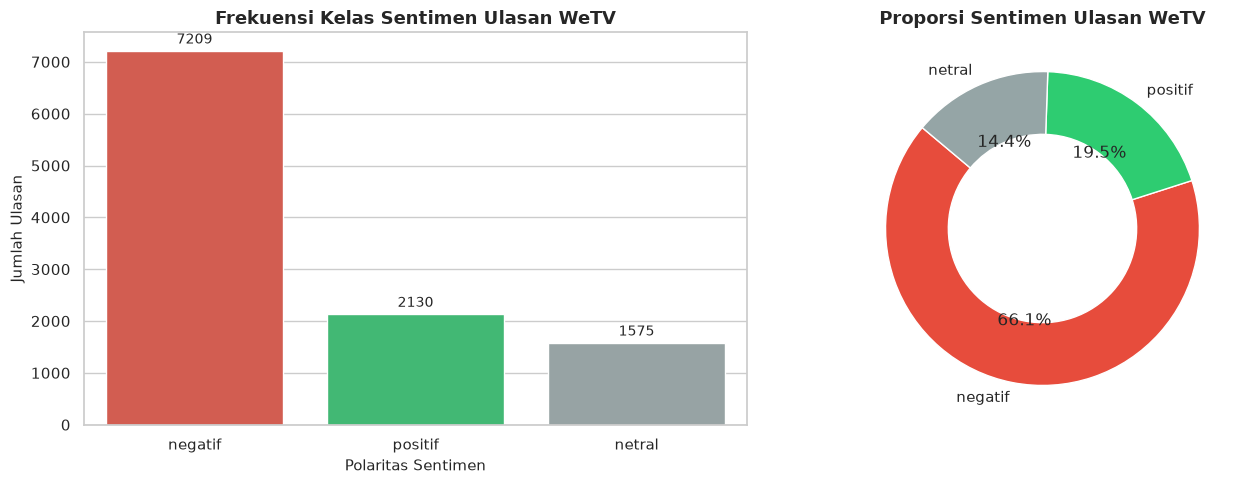

In [24]:
# Atur gaya visualisasi
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar Plot Distribusi Kelas
colors = ['#e74c3c', '#2ecc71', '#95a5a6']  # Merah (Negatif), Hijau (Positif), Abu-abu (Netral)
palette_dict = {'negatif': colors[0], 'positif': colors[1], 'netral': colors[2]}

sns.countplot(
    data=df_clean, 
    x='polarity', 
    order=['negatif', 'positif', 'netral'], 
    palette=palette_dict, 
    ax=axes[0]
)
axes[0].set_title('Frekuensi Kelas Sentimen Ulasan WeTV', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Polaritas Sentimen', fontsize=11)
axes[0].set_ylabel('Jumlah Ulasan', fontsize=11)

# Tambahkan label angka di atas setiap bar
for p in axes[0].patches:
    height = p.get_height()
    axes[0].annotate(f'{int(height)}',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 3),
                     textcoords='offset points')

# Donut / Pie Chart Proporsi
counts = df_clean['polarity'].value_counts()
labels = counts.index
axes[1].pie(
    counts, 
    labels=labels, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=[palette_dict[l] for l in labels],
    wedgeprops=dict(width=0.4, edgecolor='white')
)
axes[1].set_title('Proporsi Sentimen Ulasan WeTV', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

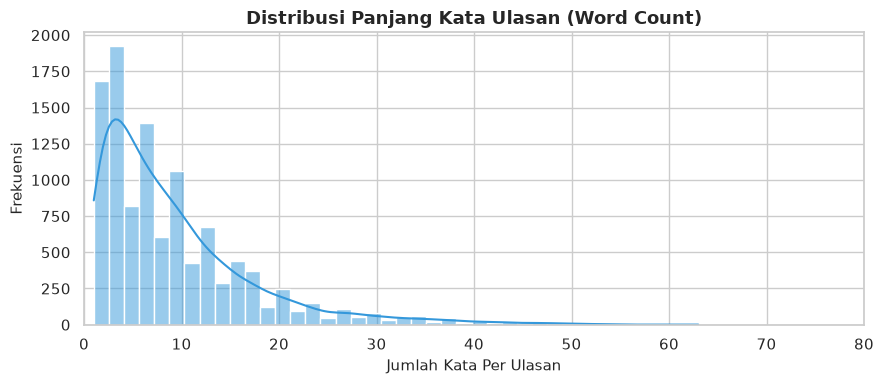

--- Ringkasan Statistik Panjang Kata ---
count    10914.000000
mean         9.295309
std          8.151678
min          1.000000
50%          7.000000
75%         12.000000
90%         20.000000
95%         26.000000
max         63.000000
Name: word_count, dtype: float64


In [25]:
# Menghitung jumlah kata per ulasan yang sudah diproses
df_clean['word_count'] = df_clean['content_processed'].apply(lambda x: len(x.split()))

plt.figure(figsize=(9, 4))
sns.histplot(df_clean['word_count'], bins=40, kde=True, color='#3498db')
plt.title('Distribusi Panjang Kata Ulasan (Word Count)', fontsize=13, fontweight='bold')
plt.xlabel('Jumlah Kata Per Ulasan', fontsize=11)
plt.ylabel('Frekuensi', fontsize=11)
plt.xlim(0, 80)  # Menyesuaikan batas umum ulasan pengguna
plt.tight_layout()
plt.show()

print("--- Ringkasan Statistik Panjang Kata ---")
print(df_clean['word_count'].describe(percentiles=[0.5, 0.75, 0.9, 0.95]))

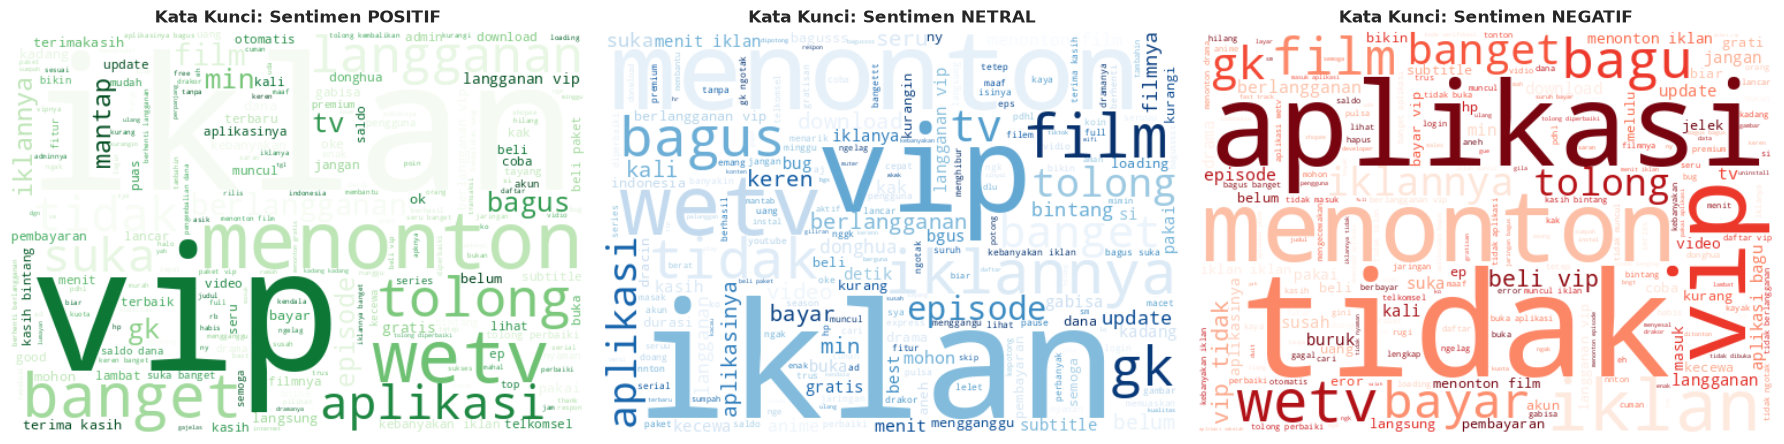

In [27]:
from wordcloud import WordCloud

# Kumpulan kata ulasan positif
pos_text = ' '.join(df_clean[df_clean['polarity'] == 'positif']['content_processed'])
wc_pos = WordCloud(width=500, height=350, background_color='white', colormap='Greens').generate(pos_text)

# Kumpulan kata ulasan netral
neu_text = ' '.join(df_clean[df_clean['polarity'] == 'netral']['content_processed'])
wc_neu = WordCloud(width=500, height=350, background_color='white', colormap='Blues').generate(neu_text)

# Kumpulan kata ulasan negatif
neg_text = ' '.join(df_clean[df_clean['polarity'] == 'negatif']['content_processed'])
wc_neg = WordCloud(width=500, height=350, background_color='white', colormap='Reds').generate(neg_text)

# Plot WordCloud 3 kelas berdampingan
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].imshow(wc_pos, interpolation='bilinear')
axes[0].set_title('Kata Kunci: Sentimen POSITIF', fontsize=12, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(wc_neu, interpolation='bilinear')
axes[1].set_title('Kata Kunci: Sentimen NETRAL', fontsize=12, fontweight='bold')
axes[1].axis('off')

axes[2].imshow(wc_neg, interpolation='bilinear')
axes[2].set_title('Kata Kunci: Sentimen NEGATIF', fontsize=12, fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
plt.show()